# Rakuten Product Text Classification

The goal of this notebook is to preprocess the product text (designation and description) for further deep learning and train a classical machine learning model (XGBoost) to predict the product category (`prdtypecode`) from the text.

# Setup and Imports

In [1]:
import os
os.chdir(os.path.expanduser('~/Desktop/Alles/Liora/Rakuten_Project'))  # change to your specific path
BASE_DIR = os.getcwd()
IMAGES_DIR = os.path.join(BASE_DIR, 'images')
DATA_DIR = os.path.join(BASE_DIR, 'text')

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from bs4 import BeautifulSoup
from langdetect import detect
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.decomposition import TruncatedSVD
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, classification_report
from xgboost import XGBClassifier

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/thomasmaisch/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# Load Data

The training input (`X_train_update.csv`) and the training labels (`Y_train_CVw08PX.csv`) are loaded and joined into a single data frame on their shared index.

In [3]:
X_train_unprocessed = pd.read_csv(DATA_DIR + '/X_train_update.csv', index_col='Unnamed: 0')
y_train_unprocessed = pd.read_csv(DATA_DIR + '/Y_train_CVw08PX.csv', index_col='Unnamed: 0')
df = X_train_unprocessed.join(y_train_unprocessed)

# Target (Product category) distribution

This plot shows how many products each category has and how many of them have a description (many descriptions are missing). The classes are clearly imbalanced, which is why we later use the weighted F1 score and SMOTE.

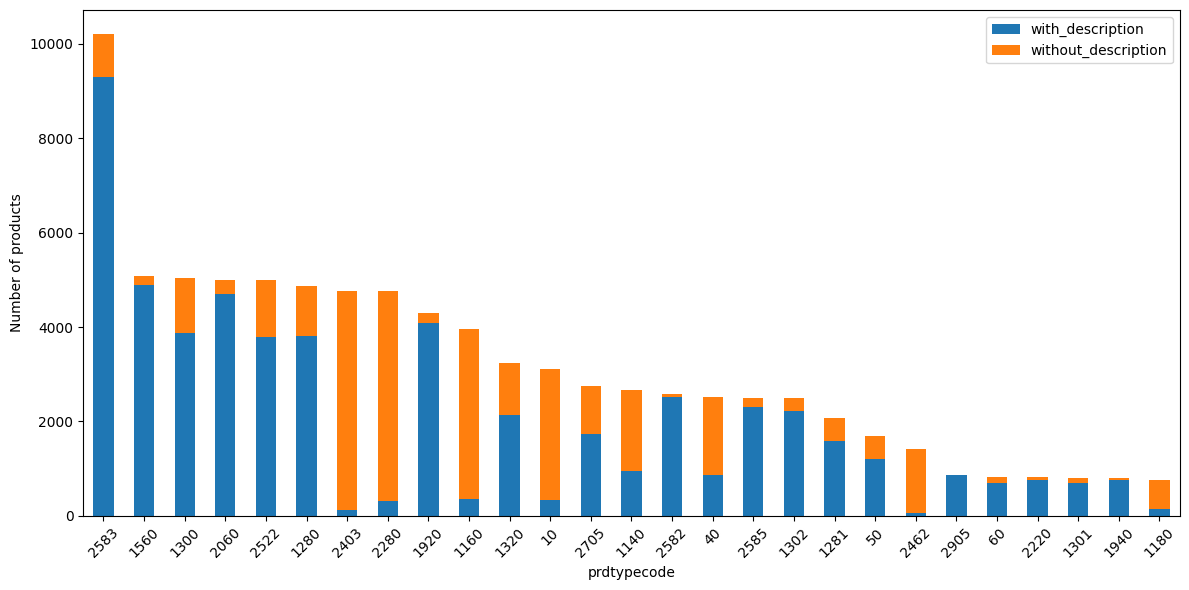

In [4]:
has_desc = df.groupby('prdtypecode')['description'].apply(lambda x: x.notna().sum())
no_desc = df.groupby('prdtypecode')['description'].apply(lambda x: x.isna().sum())

desc_df = pd.DataFrame({'with_description': has_desc, 'without_description': no_desc})
# Order by total number of products per class
order = df['prdtypecode'].value_counts().index
desc_df = desc_df.loc[order]

desc_df.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.xlabel('prdtypecode')
plt.ylabel('Number of products')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Text Preprocessing

## Merge Designation and Description

The product title (`designation`) and the `description` are merged into a single `text` column. Since many descriptions are missing (NaN), `na_rep=''` replaces missing values with an empty string so the merge does not produce NaN.

In [5]:
df['text'] = df['designation'].str.cat(df['description'], sep=' ', na_rep='')

## Remove Noise

The `remove_parasites` function cleans each text by removing URLs, email addresses and HTML tags. `BeautifulSoup` is used to strip out remaining HTML and keep only the plain text.

In [6]:
def remove_parasites(text):
    # Return an empty string if the text is missing (NaN)
    if pd.isna(text):
        return ''
    # Remove URLs (http://, https:// and www.)
    text = re.sub(r'http\S+|www\S+', '', text)
    # Remove email addresses
    text = re.sub(r'\S+@\S+\.\S+', '', text)
    # Remove invalid HTML tags like </>
    text = re.sub(r'</>', '', text)
    # Remove HTML tags and extract the plain text
    text = BeautifulSoup(text, 'html.parser').get_text()
    return text

In [7]:
df['text'] = df['text'].apply(remove_parasites)

All remaining special characters (anything that is not a letter, digit or space) are collected and replaced with spaces. Multiple spaces are then collapsed into a single space and leading/trailing spaces are removed.

In [8]:
# Collect all unique characters
all_chars = set(''.join(df['text']))
# Keep all characters that are not letters or digits
special_chars = {c for c in all_chars if not c.isalnum() and not c.isspace()}
print(special_chars)
# Build a regex pattern from all special characters (re.sub needs a regex)
pattern = '[' + re.escape(''.join(special_chars)) + ']'

# Replace all special characters with a space
df['text'] = df['text'].apply(lambda x: re.sub(pattern, ' ', x))
# Collapse multiple spaces into a single space
df['text'] = df['text'].apply(lambda x: re.sub(r'\s+', ' ', x))
# Remove leading and trailing spaces
df['text'] = df['text'].str.strip()

{'®', '…', '`', '♂', '\ufeff', '+', '•', '\x8c', '&', '"', ')', '^', '❤', '¸', '☆', '‘', '%', '§', '\x95', '\x7f', '\x93', '„', '¨', '.', '=', '€', ']', '”', '\x91', '—', '♥', '<', '¥', '(', '（', '“', ':', '\x87', '；', '\x9c', '·', '\x80', '!', '>', ';', '\x97', '\x94', '©', '̀', '）', '¯', '\u200b', '@', '±', '{', '×', '́', '\u200e', '¬', '}', '/', '¢', '̂', '?', '\\', '¿', '[', '・', '$', '\x99', '¡', '|', '★', '\xad', '：', '´', '~', "'", '*', '’', '#', '°', '-', '»', '_', '–', '\x96', '\x92', '«', '™', '£'}


## Language detection

The language of each text is detected.  `safe_detect` returns `'unknown'` if the detection fails (e.g. for very short or empty texts).

Note: language detection runs over all rows and can take a while.

In [9]:
def safe_detect(text):
    try:
        return detect(text)
    except:
        return 'unknown'

df['language'] = df['text'].apply(safe_detect)

In [10]:
df['language'].value_counts(normalize=True).head(6) * 100

language
fr    76.555655
en    14.486080
de     3.380988
nl     1.311885
ca     0.878515
it     0.741910
Name: proportion, dtype: float64

Around 90% of the text is either French (`fr`) or English (`en`). To reduce complexity, only samples whose text is identified as French (`fr`) or English (`en`) are kept.

In [12]:
df_fr_en = df.loc[(df['language'] == 'fr') | (df['language'] == 'en')]

## Remove Stopwords

French and English stopwords (very common words like *the*, *and*, *le*, *et*) carry little meaning for classification and are removed. The text is also lowercased.

In [13]:
stop_words = set(stopwords.words('french')) | set(stopwords.words('english'))
df_fr_en['text'] = df_fr_en['text'].apply(
    lambda x: ' '.join([word for word in x.lower().split() if word not in stop_words])
)

## Save preprocessed data

The preprocessed data frame is saved as `df_preprocessed.csv`. This file is the shared input for both the text model (this notebook) and the image model.

In [ ]:
df_preprocessed = df_fr_en.copy()
df_preprocessed.to_csv(os.path.join(DATA_DIR, 'df_preprocessed.csv'), index=False)

# Train Test Split

The data is split into a training and a test set (80/20). `stratify=y` keeps the class distribution the same in both sets, which is important because the classes are imbalanced.

In [ ]:
X = df_preprocessed['text']
y = df_preprocessed['prdtypecode']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=161, stratify=y
)

# Model Preparation

## TF-IDF

`TfidfVectorizer` converts the text into numeric features. Each word gets a weight based on how important it is for a document relative to the whole corpus. `max_features=50000` limits the vocabulary to the 50,000 most frequent terms.


In [15]:
vectorizer = TfidfVectorizer(max_features=50000)
X_train_idf = vectorizer.fit_transform(X_train)
X_test_idf = vectorizer.transform(X_test)

## SVD (Dimensionality Reduction)

The TF-IDF matrix is very high-dimensional and sparse. `TruncatedSVD` reduces it to 1000 dense components. `explained_variance_ratio_.sum()` shows how much of the original variance is retained by these components.


In [16]:
svd = TruncatedSVD(n_components=1000, random_state=161)
X_train_svd = svd.fit_transform(X_train_idf)
X_test_svd = svd.transform(X_test_idf)
svd.explained_variance_ratio_.sum()

np.float64(0.4142734607373332)

## SMOTE (Class Balancing)

Because the classes are imbalanced, `SMOTE` generates synthetic samples for the minority classes so that all classes are equally represented during training.

In [17]:
smote = SMOTE(random_state=161)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_svd, y_train)

# Model

## XGBoost

`LabelEncoder` maps the original class codes (e.g. 10, 40, 2280) to consecutive integers starting from 0, which XGBoost requires. The classifier is then trained on the resampled training data and evaluated on the untouched test set using the weighted F1 score.

In [18]:
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train_resampled)
y_test_encoded = le.transform(y_test)

xgb_clf = XGBClassifier(random_state=161)
xgb_clf.fit(X_train_resampled, y_train_encoded)
y_pred = xgb_clf.predict(X_test_svd)
f1_score(y_test_encoded, y_pred, average='weighted')

0.7851483486102939

The classification report shows precision, recall and F1 score for each individual class, which helps to see where the model performs well and where it struggles.

In [19]:
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_.astype(str)))

              precision    recall  f1-score   support

          10       0.49      0.54      0.51       518
          40       0.68      0.61      0.64       417
          50       0.77      0.80      0.78       305
          60       0.95      0.87      0.91       159
        1140       0.73      0.74      0.74       409
        1160       0.90      0.87      0.89       562
        1180       0.71      0.51      0.59       128
        1280       0.61      0.56      0.58       905
        1281       0.58      0.55      0.56       390
        1300       0.83      0.90      0.86       923
        1301       0.99      0.85      0.91       157
        1302       0.78      0.73      0.75       475
        1320       0.77      0.71      0.74       578
        1560       0.75      0.80      0.77      1004
        1920       0.89      0.91      0.90       850
        1940       0.89      0.82      0.85       142
        2060       0.73      0.77      0.75       986
        2220       0.83    

We can see that although we have an overall f1 score of 0.7851483486102939 some classes are performing way better than others